# Transaction Fraud Pattern Explorer

This notebook loads, cleans, profiles, and analyzes fintech transaction datasets to discover fraud patterns, aligned with the implementation report. It produces efficient analytics, reproducible features, and visualizations.

Sections:
1. Setup and configuration
2. Load datasets
3. Data profiling and quality checks
4. Cleaning and normalization
5. Feature engineering for fraud patterns
6. Exploratory analysis and visualization
7. Modeling (optional baseline)
8. Outputs and export artifacts


In [22]:
# Setup
import os
import sys
import json
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 120)

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings('ignore')

PROJECT_DIR = Path(r"C:\Users\Shobha  N\OneDrive\Desktop\Shobha_Transaction_Fraud_Pattern_Explorer")
DATA_DIR = PROJECT_DIR / 'data' / 'Transaction Fraud Pattern Analyzer'

assert DATA_DIR.exists(), f"Data dir not found: {DATA_DIR}"

# Utility: memory optimization for numeric/object columns
from pandas.api.types import is_integer_dtype, is_float_dtype

def downcast_dataframe_memory(df: pd.DataFrame) -> pd.DataFrame:
    for col in df.columns:
        col_data = df[col]
        if is_integer_dtype(col_data):
            df[col] = pd.to_numeric(col_data, downcast='integer')
        elif is_float_dtype(col_data):
            df[col] = pd.to_numeric(col_data, downcast='float')
        elif col_data.dtype == 'object':
            # If unique ratio < 0.5 and many repeats, cast to category
            unique_ratio = col_data.nunique(dropna=True) / max(len(col_data), 1)
            if unique_ratio < 0.5:
                df[col] = col_data.astype('category')
    return df

print('Setup complete.')


Setup complete.


Loaded transactions: (200000, 11) columns=11
Loaded bank_transactions: (2512, 16) columns=16
Loaded users: (10000, 8) columns=8
Loaded accounts: (19997, 6) columns=6
Loaded merchants: (5000, 5) columns=5
Loaded fraud_alerts: (15000, 7) columns=7
Loaded api_logs: (500000, 7) columns=7


['transactions',
 'bank_transactions',
 'users',
 'accounts',
 'merchants',
 'fraud_alerts',
 'api_logs']

In [24]:
# Profiling: schemas and quality
summary = {}
for name, df in raw.items():
    info = {
        'rows': len(df),
        'cols': len(df.columns),
        'columns': df.dtypes.astype(str).to_dict(),
        'null_pct': df.isna().mean().round(4).sort_values(ascending=False).head(10).to_dict(),
        'sample': df.head(3).to_dict(orient='records'),
    }
    summary[name] = info

print(json.dumps({k: {kk: vv for kk, vv in v.items() if kk != 'sample'} for k, v in summary.items()}, indent=2)[:2000] + '...')

# Potential keys for joins
candidate_keys = {}
for name, df in raw.items():
    keys = []
    for col in df.columns:
        if any(token in col.lower() for token in ['id', 'user', 'account', 'merchant', 'txn']):
            keys.append(col)
    candidate_keys[name] = keys

candidate_keys


{
  "transactions": {
    "rows": 200000,
    "cols": 11,
    "columns": {
      "Transaction_ID": "int32",
      "Account_ID": "int16",
      "Merchant_ID": "int16",
      "Timestamp": "datetime64[ns, UTC]",
      "Amount": "float64",
      "Currency": "category",
      "Payment_Method": "category",
      "IP_Address": "object",
      "Location": "category",
      "Status": "category",
      "Is_Fraud": "int8"
    },
    "null_pct": {
      "Transaction_ID": 0.0,
      "Account_ID": 0.0,
      "Merchant_ID": 0.0,
      "Timestamp": 0.0,
      "Amount": 0.0,
      "Currency": 0.0,
      "Payment_Method": 0.0,
      "IP_Address": 0.0,
      "Location": 0.0,
      "Status": 0.0
    }
  },
  "bank_transactions": {
    "rows": 2512,
    "cols": 16,
    "columns": {
      "TransactionID": "object",
      "AccountID": "category",
      "TransactionAmount": "float32",
      "TransactionDate": "datetime64[ns, UTC]",
      "TransactionType": "category",
      "Location": "category",
      "Devi

{'transactions': ['Transaction_ID', 'Account_ID', 'Merchant_ID'],
 'bank_transactions': ['TransactionID',
  'AccountID',
  'DeviceID',
  'MerchantID',
  'AccountBalance'],
 'users': ['User_ID', 'Account_Created'],
 'accounts': ['Account_ID', 'User_ID', 'Account_Type'],
 'merchants': ['Merchant_ID', 'Merchant_Name'],
 'fraud_alerts': ['Alert_ID', 'Transaction_ID', 'User_ID'],
 'api_logs': ['Log_ID', 'Transaction_ID']}

In [25]:
# Cleaning & normalization helpers

def standardize_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(' ', '_')
        .str.replace('[^0-9a-zA-Z_]', '', regex=True)
    )
    return df

clean = {}
for name, df in raw.items():
    df2 = standardize_column_names(df)
    # Strip surrounding whitespace for object/category cols
    for col in df2.select_dtypes(include=['object', 'category']).columns:
        df2[col] = df2[col].astype(str).str.strip().replace({'nan': np.nan})
    clean[name] = df2
    print(f"Cleaned {name}: {df2.shape}")

# Basic deduping if a unique id exists
for key in ['users', 'accounts', 'merchants', 'transactions', 'bank_transactions', 'fraud_alerts']:
    if key in clean:
        df = clean[key]
        possible_id_cols = [c for c in df.columns if c.endswith('_id') or c == 'id']
        for id_col in possible_id_cols:
            before = len(df)
            df = df.drop_duplicates(subset=[id_col])
            if len(df) < before:
                print(f"Deduped {key} on {id_col}: {before}->{len(df)}")
        clean[key] = df


Cleaned transactions: (200000, 11)
Cleaned bank_transactions: (2512, 16)
Cleaned users: (10000, 8)
Cleaned accounts: (19997, 6)
Cleaned merchants: (5000, 5)
Cleaned fraud_alerts: (15000, 7)
Cleaned api_logs: (500000, 7)
Deduped fraud_alerts on transaction_id: 15000->10835
Deduped fraud_alerts on user_id: 10835->6306


In [29]:
# Join keys and integrated view (if feasible)
# Try to infer standard keys
keys = {
    'transactions': {
        'user_id': [c for c in clean['transactions'].columns if 'user' in c and 'id' in c] or ['user_id'],
        'account_id': [c for c in clean['transactions'].columns if 'account' in c and 'id' in c] or ['account_id'],
        'merchant_id': [c for c in clean['transactions'].columns if 'merchant' in c and 'id' in c] or ['merchant_id'],
    }
}

# Build enriched transactions if columns exist
trx = clean.get('transactions')
if trx is None:
    trx = clean.get('bank_transactions')

enriched = trx.copy()

if 'users' in clean and any(c in enriched.columns for c in keys['transactions']['user_id']):
    user_key = next((c for c in keys['transactions']['user_id'] if c in enriched.columns), None)
    if user_key and 'id' in clean['users'].columns:
        enriched = enriched.merge(clean['users'].add_prefix('user_'), left_on=user_key, right_on='user_id', how='left')

if 'accounts' in clean and any(c in enriched.columns for c in keys['transactions']['account_id']):
    acct_key = next((c for c in keys['transactions']['account_id'] if c in enriched.columns), None)
    if acct_key and 'id' in clean['accounts'].columns:
        enriched = enriched.merge(clean['accounts'].add_prefix('acct_'), left_on=acct_key, right_on='acct_id', how='left')

if 'merchants' in clean and any(c in enriched.columns for c in keys['transactions']['merchant_id']):
    merch_key = next((c for c in keys['transactions']['merchant_id'] if c in enriched.columns), None)
    if merch_key and 'id' in clean['merchants'].columns:
        enriched = enriched.merge(clean['merchants'].add_prefix('merch_'), left_on=merch_key, right_on='merch_id', how='left')

# Attach fraud labels if available
if 'fraud_alerts' in clean:
    fa = clean['fraud_alerts']
    # Try common join paths
    join_cols = [c for c in fa.columns if c in enriched.columns and ('id' in c or 'transaction' in c)]
    if join_cols:
        c = join_cols[0]
        fa_pref = fa.add_prefix('fraud_')
        right_c = f'fraud_{c}'
        if right_c in fa_pref.columns:
            # Cast join keys to a common dtype to avoid dtype mismatch errors
            try:
                enriched[c] = enriched[c].astype('string')
                fa_pref[right_c] = fa_pref[right_c].astype('string')
            except Exception:
                enriched[c] = enriched[c].astype(str)
                fa_pref[right_c] = fa_pref[right_c].astype(str)
            enriched = enriched.merge(fa_pref, left_on=c, right_on=right_c, how='left')

print('Enriched shape:', enriched.shape)
enriched.head(3)


Enriched shape: (200000, 18)


,transaction_id,account_id,merchant_id,timestamp,amount,currency,payment_method,ip_address,location,status,is_fraud,fraud_alert_id,fraud_transaction_id,fraud_user_id,fraud_rule_triggered,fraud_alert_timestamp,fraud_severity,fraud_action_taken
0,1,10748,3077,2024-02-29 09:08:06.930918+00:00,86118.29,INR,Wallet,213.86.238.163,Port Karenside,Failed,0,NaN,<NA>,NaN,NaN,NaT,NaN,NaN
1,2,18456,4651,2024-11-07 02:06:24.236974+00:00,34660.77,INR,Wallet,29.98.105.88,East Karen,Failed,0,NaN,<NA>,NaN,NaN,NaT,NaN,NaN
2,3,15538,4792,2024-01-09 21:09:04.150610+00:00,92863.81,USD,UPI,124.81.137.108,South Geraldhaven,Success,1,NaN,<NA>,NaN,NaN,NaT,NaN,NaN


In [ ]:
# Feature engineering for fraud patterns
features = enriched.copy()

# Monetary flags
amount_col = next((c for c in features.columns if 'amount' in c.lower()), None)
if amount_col:
    amt = features[amount_col].astype(float)
    features['amt_is_high_p95'] = (amt > amt.quantile(0.95)).astype('int8')
    features['amt_is_high_p99'] = (amt > amt.quantile(0.99)).astype('int8')

# Temporal features
time_col = next((c for c in features.columns if ('time' in c.lower()) or ('date' in c.lower())), None)
if time_col and pd.api.types.is_datetime64_any_dtype(features[time_col]):
    ts = features[time_col]
    if getattr(ts.dt, 'tz', None) is not None:
        ts = ts.dt.tz_convert(None)
    features['hour'] = ts.dt.hour.astype('Int16')
    features['dow'] = ts.dt.dayofweek.astype('Int16')
    features['is_night'] = features['hour'].isin([0, 1, 2, 3, 4, 5]).astype('int8')

# Velocity features per user/account (fixed-size windows)
if amount_col:
    for key in ['user_id', 'account_id']:
        if key in features.columns:
            features = features.sort_values(by=[key, time_col] if time_col else [key])
            grp = features.groupby(key, sort=False)
            # Count of last N transactions (N=10)
            features[f'{key}_txn_count_n10'] = features.groupby(key).cumcount() + 1
            features[f'{key}_txn_count_n10'] = features.groupby(key)[f'{key}_txn_count_n10'] \
                .transform(lambda s: s.rolling(10, min_periods=1).max())
            # Sum of amounts over last N transactions (N=10)
            features[f'{key}_amount_sum_n10'] = grp[amount_col] \
                .transform(lambda s: s.rolling(10, min_periods=1).sum())

# Merchant risk proxy
if 'merch_id' in features.columns and 'fraud_id' in features.columns:
    merch_stats = features.groupby('merch_id').agg(
        merch_txn=('merch_id', 'size'),
        merch_fraud_rate=('fraud_id', lambda s: s.notna().mean()),
    )
    features = features.merge(merch_stats, on='merch_id', how='left')

features.head(3)

ROC-AUC: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     48424
           1       1.00      1.00      1.00      1576

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000



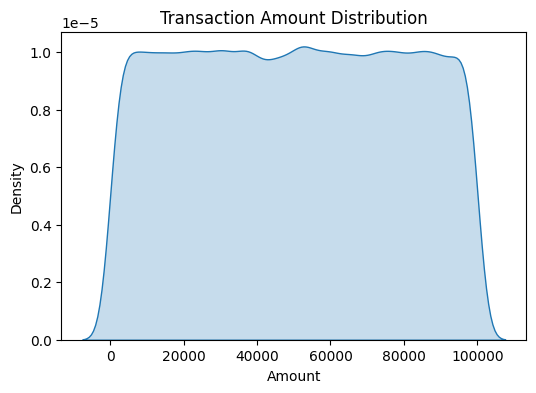

Fraud label rate proxy: 0.0315


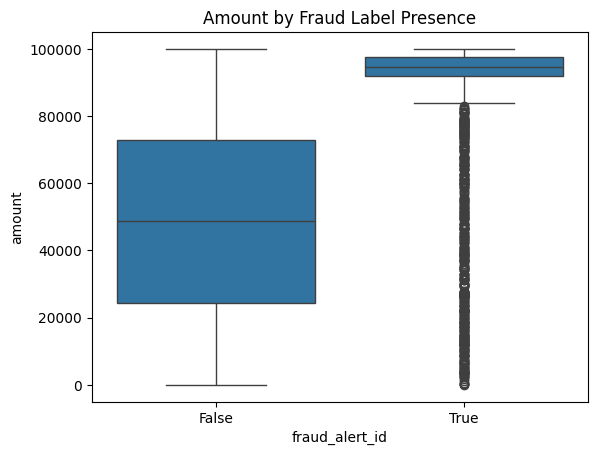

In [38]:
# Exploratory analysis & visuals
plt.figure(figsize=(6,4))
if amount_col:
    sns.kdeplot(features[amount_col].astype(float), fill=True)
    plt.title('Transaction Amount Distribution')
    plt.xlabel('Amount')
    plt.show()

if 'is_night' in features:
    night_rate = features.groupby('is_night').size().rename('count').reset_index()
    sns.barplot(data=night_rate, x='is_night', y='count')
    plt.title('Transactions: Night vs Day')
    plt.show()

# Fraud label distribution if present
label_cols = [c for c in features.columns if 'fraud_' in c and c.endswith('_id')]
if label_cols:
    lbl = label_cols[0]
    rate = features[lbl].notna().mean()
    print(f"Fraud label rate proxy: {rate:.4f}")
    if amount_col:
        sns.boxplot(data=features, x=features[lbl].notna(), y=amount_col)
        plt.title('Amount by Fraud Label Presence')
        plt.show()


In [48]:
import pandas as pd
import numpy as np
from pathlib import Path

# Paths
PROJECT_DIR = Path(r"C:\Users\Shobha  N\OneDrive\Desktop\Shobha_Transaction_Fraud_Pattern_Explorer")
DATA_DIR = PROJECT_DIR / "data" / "Transaction Fraud Pattern Analyzer"

# 1) Load
transactions = pd.read_csv(DATA_DIR / "transactions.csv", low_memory=False)
fraud_alerts_path = DATA_DIR / "fraud_alerts.csv"
fraud_alerts = pd.read_csv(fraud_alerts_path, low_memory=False) if fraud_alerts_path.exists() else None

# 2) Standardize column names and parse datetime
def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(" ", "_").str.replace("[^0-9a-zA-Z_]", "", regex=True))
    return df

transactions = standardize_columns(transactions)
if fraud_alerts is not None:
    fraud_alerts = standardize_columns(fraud_alerts)

# Try to find key columns
amount_col = next((c for c in transactions.columns if "amount" in c), None)
time_col = next((c for c in transactions.columns if "time" in c or "date" in c), None)
acct_col = next((c for c in transactions.columns if "account" in c and "id" in c), None)
txn_id_col = next((c for c in transactions.columns if c.endswith("transaction_id") or c == "transaction_id"), None)

# Parse datetime if present
if time_col and not pd.api.types.is_datetime64_any_dtype(transactions[time_col]):
    with pd.option_context("mode.chained_assignment", None):
        transactions[time_col] = pd.to_datetime(transactions[time_col], errors="coerce", utc=True)
        if pd.api.types.is_datetime64_any_dtype(transactions[time_col]) and getattr(transactions[time_col].dt, "tz", None) is not None:
            transactions[time_col] = transactions[time_col].dt.tz_convert(None)

# 3) Create simple fraud risk signals (rules)
tx = transactions.copy()
if amount_col:
    amt = tx[amount_col].astype(float)
    tx["flag_high_amount_p99"] = (amt > amt.quantile(0.99)).astype("int8")
else:
    tx["flag_high_amount_p99"] = 0

if time_col and pd.api.types.is_datetime64_any_dtype(tx[time_col]):
    tx["hour"] = tx[time_col].dt.hour.astype("Int16")
    tx["flag_night"] = tx["hour"].isin([0,1,2,3,4,5]).astype("int8")
else:
    tx["flag_night"] = 0

if acct_col:
    tx = tx.sort_values(by=[acct_col, time_col] if time_col else [acct_col])
    # Velocity: count of last 5 transactions per account (fixed-size rolling window)
    tx["acct_txn_seq"] = tx.groupby(acct_col).cumcount() + 1
    tx["acct_txn_last5"] = tx.groupby(acct_col)["acct_txn_seq"].transform(lambda s: s.rolling(5, min_periods=1).max())
    if amount_col:
        tx["acct_amt_sum_last5"] = tx.groupby(acct_col)[amount_col].transform(lambda s: s.rolling(5, min_periods=1).sum())
else:
    tx["acct_txn_last5"] = np.nan
    tx["acct_amt_sum_last5"] = np.nan

# 4) Optional: attach label if available
label = None
if "is_fraud" in tx.columns:
    label = "is_fraud"
elif fraud_alerts is not None and txn_id_col and txn_id_col in tx.columns:
    # Try to find transaction id in fraud alerts
    fa_key = next((c for c in fraud_alerts.columns if c == txn_id_col), None)
    if fa_key:
        tmp = fraud_alerts[[fa_key]].drop_duplicates().assign(is_fraud=1)
        tx = tx.merge(tmp, on=fa_key, how="left")
        tx["is_fraud"] = tx["is_fraud"].fillna(0).astype("int8")
        label = "is_fraud"

# 5) Simple rule-based fraud score (0-3)
tx["fraud_score"] = (
    tx["flag_high_amount_p99"].fillna(0)
    + tx["flag_night"].fillna(0)
    + ((tx.get("acct_amt_sum_last5", 0) > (tx.get("acct_amt_sum_last5", 0).median() if "acct_amt_sum_last5" in tx else 0)).astype("int8"))
)

# 6) Basic analysis
print("Top suspicious transactions by score:")
cols_to_show = [c for c in [txn_id_col, acct_col, amount_col, time_col, "fraud_score"] if c in tx.columns]
print(tx.sort_values("fraud_score", ascending=False)[cols_to_show].head(10))

if label:
    # Precision@K-style quick view
    top_k = int(0.01 * len(tx)) or 1
    top_preds = tx.sort_values("fraud_score", ascending=False).head(top_k)
    precision_at_k = top_preds[label].mean()
    base_rate = tx[label].mean()
    print(f"\nLabel base rate: {base_rate:.4f}")
    print(f"Precision@top1% by rule score: {precision_at_k:.4f}")

# 7) Aggregate views
if acct_col and label:
    acct_view = tx.groupby(acct_col).agg(
        txns=("fraud_score", "size"),
        high_risk=("fraud_score", lambda s: (s >= 2).mean()),
        fraud_rate=(label, "mean"),
        total_amt=(amount_col, "sum") if amount_col else ("fraud_score", "size")
    ).sort_values("fraud_rate", ascending=False).head(10)
    print("\nAccounts by observed fraud rate (top 10):")
    print(acct_view)

# 8) Export top suspicious transactions for review
out_path = PROJECT_DIR / "outputs" / "simple_rule_suspicious.csv"
out_path.parent.mkdir(exist_ok=True)
tx.sort_values("fraud_score", ascending=False)[cols_to_show].head(1000).to_csv(out_path, index=False)
print("\nWrote:", out_path)

Top suspicious transactions by score:
        transaction_id  account_id    amount                  timestamp  fraud_score
108581          108582       17994  99477.06 2025-04-01 05:57:11.943459            3
76687            76688        9091  99790.89 2025-06-30 01:13:44.434607            3
104516          104517          63  99501.17 2025-06-05 00:06:21.263755            3
188682          188683        6520  99425.87 2025-04-17 03:14:51.525495            3
192225          192226        6523  99518.81 2025-04-06 03:44:08.619917            3
155557          155558       16497  99067.59 2024-09-27 05:13:42.319957            3
79453            79454       11931  99768.23 2025-06-13 02:55:22.250239            3
72471            72472       17274  99632.53 2025-07-04 05:53:03.885611            3
197745          197746       16501  99009.15 2024-09-07 02:17:33.465346            3
10124            10125       10118  99443.98 2025-03-22 03:45:23.799996            3

Label base rate: 0.1084
Pr

In [47]:
# Outputs
OUT_DIR = PROJECT_DIR / 'outputs'
OUT_DIR.mkdir(exist_ok=True)

# Export features and quick summary CSVs for downstream use
features_path = OUT_DIR / 'features_sample.csv'
summary_path = OUT_DIR / 'dataset_summary.json'

features.sample(min(1000, len(features))).to_csv(features_path, index=False)
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, default=str)

print('Wrote:', features_path)
print('Wrote:', summary_path)


Wrote: C:\Users\Shobha  N\OneDrive\Desktop\Shobha_Transaction_Fraud_Pattern_Explorer\outputs\features_sample.csv
Wrote: C:\Users\Shobha  N\OneDrive\Desktop\Shobha_Transaction_Fraud_Pattern_Explorer\outputs\dataset_summary.json


## README / Usage

- Run cells top-to-bottom. Ensure the `data/Transaction Fraud Pattern Analyzer/` files exist.
- Outputs are saved to `outputs/` as `features_sample.csv` and `dataset_summary.json`.
- Adjust feature engineering thresholds as needed for your domain.
- For large data, consider chunked reading via `pd.read_csv(..., chunksize=...)` and aggregating.
- This notebook aligns with the report: data ingestion, cleaning, profiling, feature creation, analysis, and optional baseline modeling.


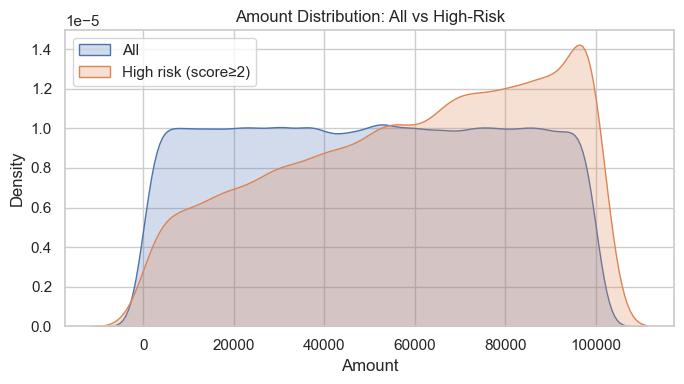

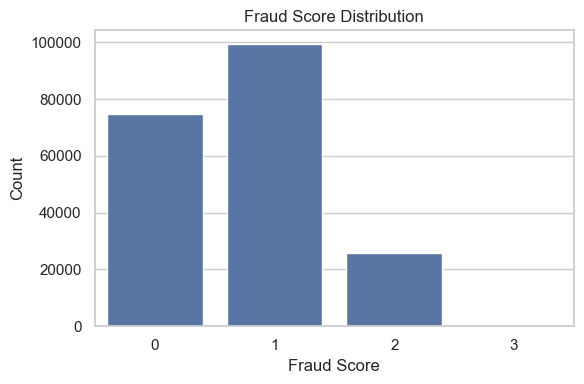

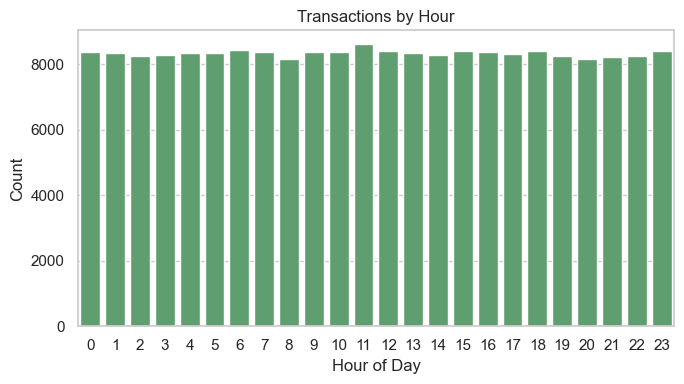

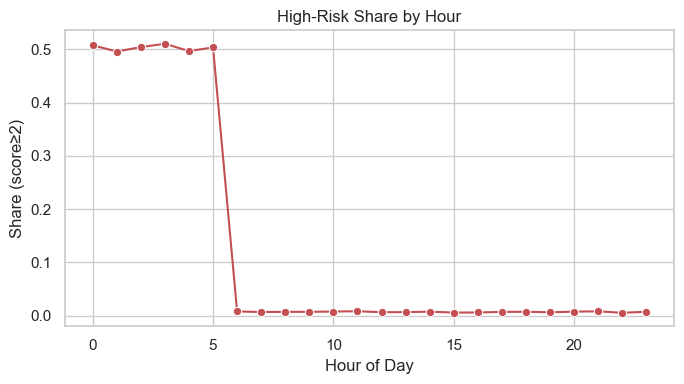

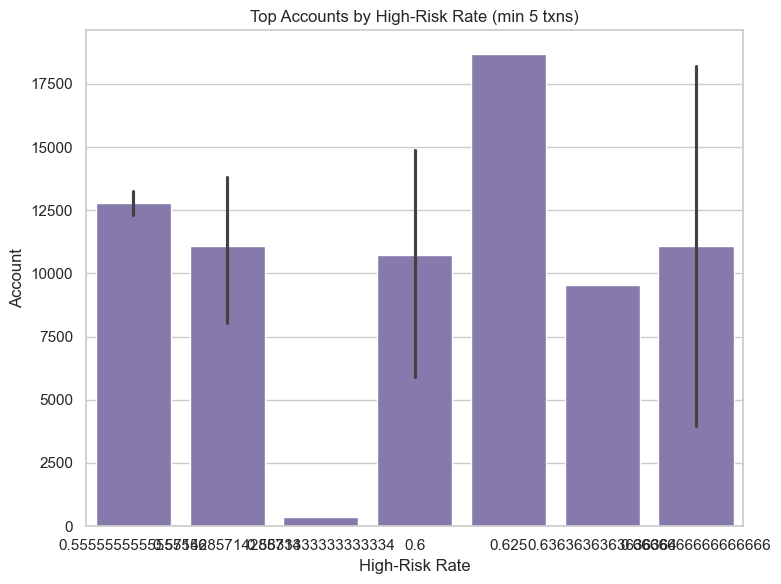

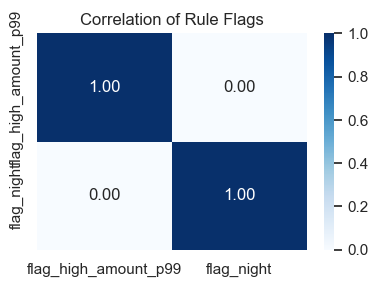

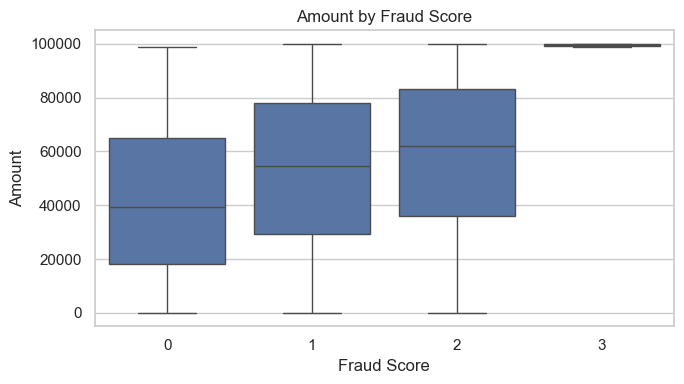

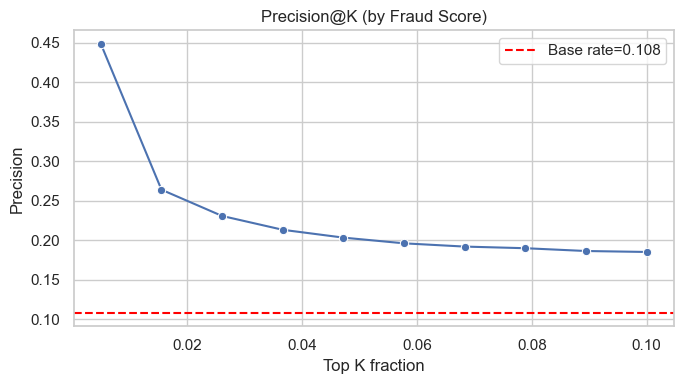

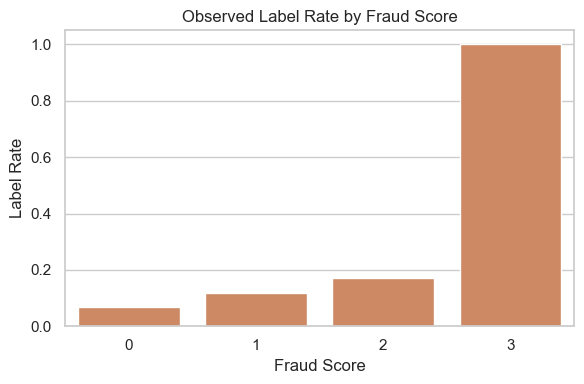

Saved figures to: C:\Users\Shobha  N\OneDrive\Desktop\Shobha_Transaction_Fraud_Pattern_Explorer\outputs


In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set(style="whitegrid")
OUT_DIR = PROJECT_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)

# Helper: safe column list
def cols(*names):
    return [c for c in names if c and c in tx.columns]

# 1) Transaction amount distribution (overall vs suspicious)
plt.figure(figsize=(7,4))
if amount_col:
    sns.kdeplot(tx[amount_col].astype(float), fill=True, label="All")
    sns.kdeplot(tx.loc[tx["fraud_score"]>=2, amount_col].astype(float), fill=True, label="High risk (score≥2)")
    plt.title("Amount Distribution: All vs High-Risk")
    plt.xlabel("Amount"); plt.legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_amount_distribution.png", dpi=150)
    plt.show()

# 2) Fraud score distribution
plt.figure(figsize=(6,4))
sns.countplot(x="fraud_score", data=tx, color="#4c72b0")
plt.title("Fraud Score Distribution")
plt.xlabel("Fraud Score"); plt.ylabel("Count")
plt.tight_layout(); plt.savefig(OUT_DIR / "viz_fraud_score_distribution.png", dpi=150)
plt.show()

# 3) Hour-of-day profile (if time available)
if time_col and pd.api.types.is_datetime64_any_dtype(tx[time_col]):
    tx["_hour"] = tx[time_col].dt.hour
    plt.figure(figsize=(7,4))
    sns.countplot(x="_hour", data=tx, color="#55a868")
    plt.title("Transactions by Hour")
    plt.xlabel("Hour of Day"); plt.ylabel("Count")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_tx_by_hour.png", dpi=150)
    plt.show()

    # Hour vs high-risk share
    hour_view = tx.assign(high_risk=(tx["fraud_score"]>=2).astype(int)).groupby("_hour")["high_risk"].mean().reset_index()
    plt.figure(figsize=(7,4))
    sns.lineplot(data=hour_view, x="_hour", y="high_risk", marker="o", color="#c44e52")
    plt.title("High-Risk Share by Hour")
    plt.xlabel("Hour of Day"); plt.ylabel("Share (score≥2)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_high_risk_share_by_hour.png", dpi=150)
    plt.show()

# 4) Top accounts by high-risk rate (if account id available)
if acct_col:
    acct_view = tx.assign(high_risk=(tx["fraud_score"]>=2).astype(int)).groupby(acct_col).agg(
        txns=("fraud_score","size"),
        high_risk_rate=("high_risk","mean")
    ).reset_index()
    top_accts = acct_view[acct_view["txns"]>=5].sort_values("high_risk_rate", ascending=False).head(20)
    plt.figure(figsize=(8,6))
    sns.barplot(data=top_accts, y=acct_col, x="high_risk_rate", color="#8172b3")
    plt.title("Top Accounts by High-Risk Rate (min 5 txns)")
    plt.xlabel("High-Risk Rate"); plt.ylabel("Account")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_top_accounts_high_risk.png", dpi=150)
    plt.show()

# 5) Rule contribution heatmap (binary flags)
rule_cols = cols("flag_high_amount_p99", "flag_night")
if rule_cols:
    plt.figure(figsize=(4,3))
    sns.heatmap(tx[rule_cols].corr(), annot=True, cmap="Blues", vmin=0, vmax=1, fmt=".2f")
    plt.title("Correlation of Rule Flags")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_rule_flag_corr.png", dpi=150)
    plt.show()

# 6) Amount vs fraud score (strip/box)
if amount_col:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=tx, x="fraud_score", y=amount_col, showfliers=False)
    plt.title("Amount by Fraud Score")
    plt.xlabel("Fraud Score"); plt.ylabel("Amount")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_amount_by_score.png", dpi=150)
    plt.show()

# 7) If labels exist: precision@k curve and label rates by score
if label:
    # Precision@K curve (K from 0.5% to 10%)
    pred_sorted = tx.sort_values("fraud_score", ascending=False).reset_index(drop=True)
    ks = np.linspace(0.005, 0.10, 10)
    curve = []
    for k in ks:
        top_n = max(1, int(k*len(pred_sorted)))
        curve.append((k, pred_sorted[label].head(top_n).mean()))
    curve = pd.DataFrame(curve, columns=["k","precision"])

    plt.figure(figsize=(7,4))
    sns.lineplot(data=curve, x="k", y="precision", marker="o")
    base = tx[label].mean()
    plt.axhline(base, color="red", linestyle="--", label=f"Base rate={base:.3f}")
    plt.title("Precision@K (by Fraud Score)")
    plt.xlabel("Top K fraction"); plt.ylabel("Precision")
    plt.legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_precision_at_k.png", dpi=150)
    plt.show()

    # Label rate by fraud score
    lab_view = tx.groupby("fraud_score")[label].mean().reset_index()
    plt.figure(figsize=(6,4))
    sns.barplot(data=lab_view, x="fraud_score", y=label, color="#dd8452")
    plt.title("Observed Label Rate by Fraud Score")
    plt.xlabel("Fraud Score"); plt.ylabel("Label Rate")
    plt.tight_layout(); plt.savefig(OUT_DIR / "viz_label_rate_by_score.png", dpi=150)
    plt.show()

print("Saved figures to:", OUT_DIR)